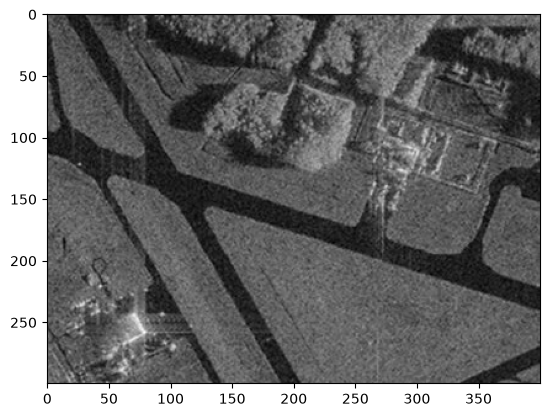

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

image = cv2.imread('sar_2.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY).astype(np.float32)
plt.imshow(image_gray, cmap="gray")

In [2]:
# Алгоритм разрастания регионов

def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])
    if abs(av_val - img[point]) <= T:
        return True
    return False



In [12]:
def region_growing(image, seed_point, homo_fun, r, T):
    mask = np.zeros(image.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image.shape, np.uint8)
        for i in range(r, image.shape[0] - r):
            for j in range(r, image.shape[1] - r):
                if mask[i, j] == 0 and mask[i-r:i+r, j-r:j+r].sum() > 0:
                    if homo_fun(image, mask, (i, j), T):
                        local_mask[i, j] = 1
        count = np.count_nonzero(local_mask)
        print(count)
        mask += local_mask
    return mask * 255

33
68
109
139
197
197
223
226
201
162
168
163
152
156
151
144
127
122
119
93
64
117
14
4
0
12
15
15
19
23
23
11
0
17
36
83
166
188
181
192
224
227
230
235
198
207
205
203
200
279
202
219
229
251
253
259
273
286
300
286
270
285
294
289
255
154
173
182
165
188
168
186
204
214
214
233
298
309
343
346
726
384
362
378
318
266
269
263
86
70
76
51
47
35
17
7
0
23
64
124
171
203
241
280
329
346
381
396
425
505
433
470
445
496
556
578
583
613
621
660
682
683
517
401
371
364
338
335
335
316
297
299
298
279
262
275
246
231
211
203
204
194
178
173
167
125
68
60
58
58
54
50
46
39
31
18
11
9
0
29
86
103
130
187
230
310
237
210
224
159
129
96
70
34
29
21
8
0
25
82
77
99
108
128
153
166
179
208
207
228
248
257
232
275
299
292
300
331
342
356
384
354
383
401
369
438
428
412
413
430
388
319
314
294
278
276
287
273
279
293
269
259
257
264
259
254
243
245
236
216
209
194
190
171
168
162
140
146
124
128
128
128
127
106
102
95
92
85
90
87
75
68
60
58
58
54
50
46
39
31
18
11
9
0


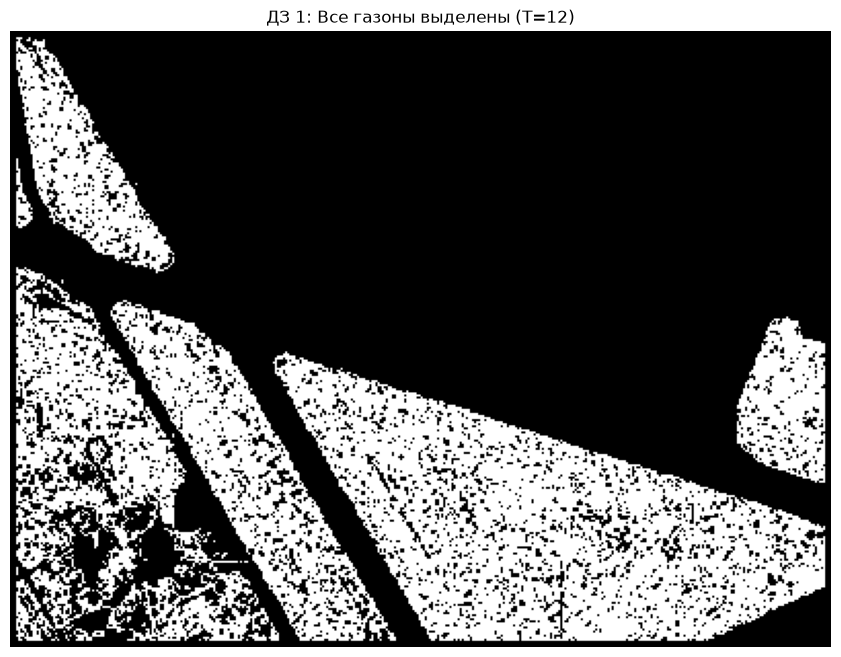

In [13]:
seeds = [(50, 25), (75, 5), (200, 100), (220, 250), (175, 375), (290, 298)] 

masks = []
for seed in seeds:
    m = region_growing(image_gray, seed, homo_average, r=3, T=12)
    masks.append(m)

mask_total = np.zeros_like(masks[0])
for m in masks:
    mask_total = np.maximum(mask_total, m)

plt.figure(figsize=(12, 8))
plt.imshow(mask_total, cmap="gray")
plt.title("ДЗ 1: Все газоны выделены")
plt.axis("off")
plt.show()

8
16
43
61
75
98
113
124
132
151
168
209
209
237
229
250
308
285
297
279
297
307
314
340
335
323
422
380
364
372
392
409
416
398
350
221
228
219
225
209
207
203
206
208
193
191
182
178
186
189
186
180
169
168
167
156
150
144
134
101
98
113
109
97
107
112
111
99
103
110
109
103
102
110
110
111
104
276
105
104
103
104
100
99
100
99
96
90
84
86
88
89
83
82
81
85
81
81
75
69
71
78
74
70
67
66
67
64
66
66
68
63
59
60
58
54
49
53
54
53
50
45
45
47
49
48
44
41
37
38
36
31
33
28
32
32
27
29
26
27
25
24
22
20
19
14
11
11
8
5
7
4
0


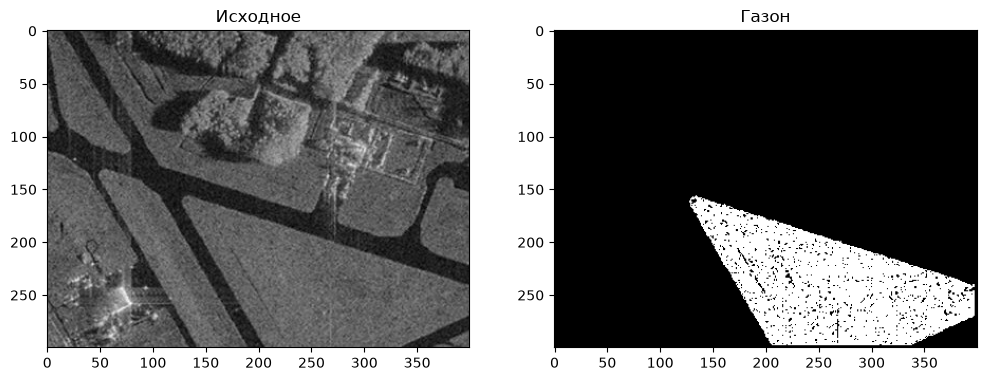

In [18]:
seed_point = (230, 280)     
r = 2
T = 15

mask_avg = region_growing(image_gray, seed_point, homo_average, r, T)

plt.figure(figsize=(12,5))
plt.subplot(1,2,1); plt.imshow(image_gray, cmap='gray'); plt.title('Исходное')
plt.subplot(1,2,2); plt.imshow(mask_avg,   cmap='gray'); plt.title('Газон')
plt.show()

In [16]:
def homo_median(img, mask, point, T):
    med = np.median(img[mask > 0])
    return abs(float(img[point]) - med) <= T

31
76
128
172
217
239
312
362
394
459
486
537
578
617
738
568
500
566
567
580
563
539
538
517
487
506
492
495
469
439
423
421
392
561
372
358
338
308
305
284
259
241
235
226
216
193
184
179
139
77
68
61
64
56
53
49
42
33
22
14
10
0


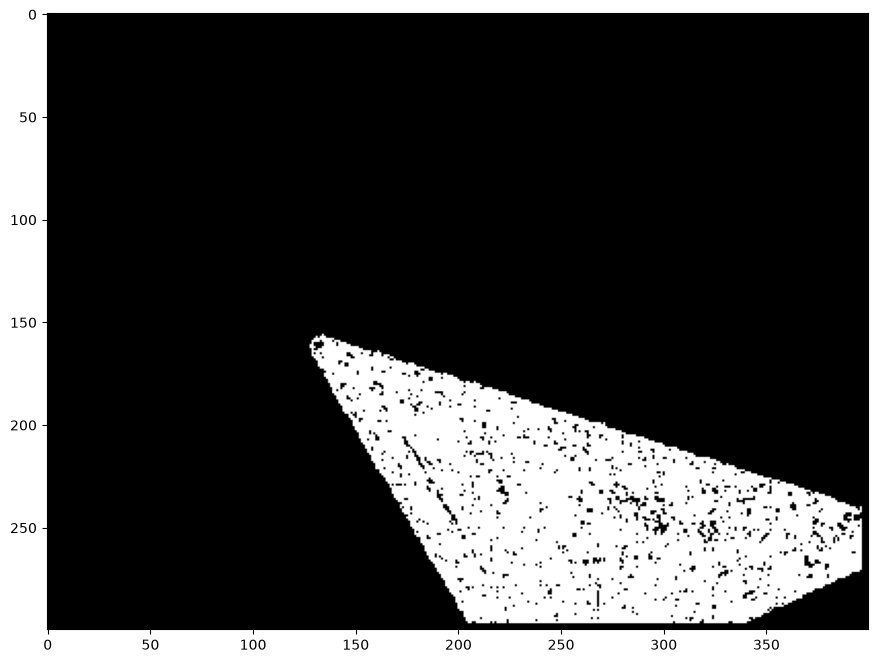

In [17]:
seed_point = (250, 250)
mask2 = region_growing(image_gray, seed_point, homo_median, 3, 15)

plt.figure(figsize=(12, 8))
plt.imshow(mask2, cmap="gray")

In [21]:
print('Сравнили два критерия: homo_average (сравнивает яркость точки со средним по области) и homo_median (с медианой). Это разные критерии: среднее сильно тянется выбросами, медиана - нет.В результате homo_average разливается шире и дольше (~155 проходов), а homo_median - быстрее(~63 прохода), маска точнее по границам. ')



Сравнили два критерия: homo_average (сравнивает яркость точки со средним по области) и homo_median (с медианой). Это разные критерии: среднее сильно тянется выбросами, медиана - нет.В результате homo_average разливается шире и дольше (~155 проходов), а homo_median - быстрее(~63 прохода), маска точнее по границам. 


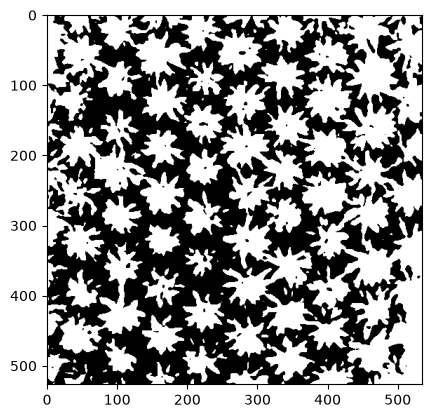

In [27]:
from scipy.ndimage import maximum_filter
image = cv2.imread('palm.jpg')


image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

blur = cv2.GaussianBlur(image_gray, (9,9), 0)
ret, thresh = cv2.threshold(blur,0,255, cv2.THRESH_BINARY+cv2.THRESH_OTSU)
plt.imshow(thresh, cmap="gray")

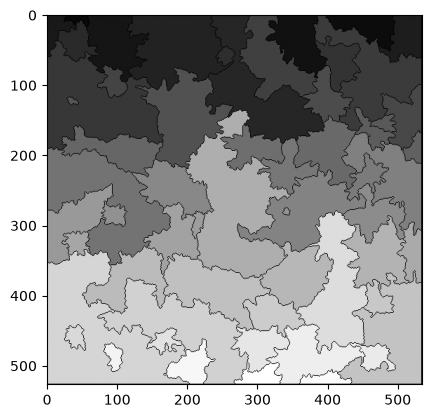

In [28]:
dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5) 
plt.imshow(dist, cmap="gray")

ret, sure_fg = cv2.threshold(dist, 0.4 * dist.max(), 255, cv2.THRESH_BINARY) 
plt.imshow(sure_fg, cmap="gray")

sure_fg = sure_fg.astype(np.uint8)
ret, markers = cv2.connectedComponents(sure_fg) 
plt.imshow(markers, cmap="gray")

markers = cv2.watershed(image, markers)
plt.imshow(markers, cmap="gray")

Найдено пальм: 59


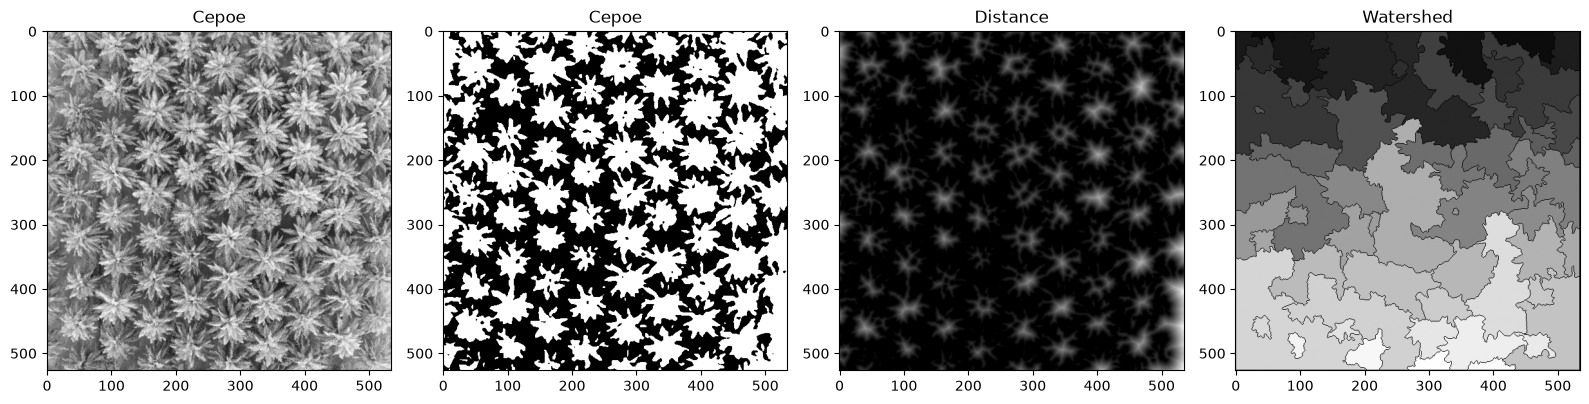

In [32]:
n_palms = ret - 1           

print('Найдено пальм:', n_palms)

plt.figure(figsize=(16, 5))
plt.subplot(1, 4, 1); plt.imshow(image_gray, cmap='gray'); plt.title('Серое')
plt.subplot(1, 4, 2); plt.imshow(thresh, cmap='gray'); plt.title('Бинарная маска (Otsu)')
plt.subplot(1, 4, 3); plt.imshow(dist,       cmap='gray'); plt.title('Distance')
plt.subplot(1, 4, 4); plt.imshow(markers, cmap='gray'); plt.title('Watershed')

plt.tight_layout()
plt.show()